Creamos un dataset con numpy para darle uso de practica y guardamos el data set en formato csv, comfiguramos la semilla y mostramos el archivo de descarga. Llamamos a las librerias.

### Carga del Dataset

Comenzamos cargando nuestro dataset de estudiantes para iniciar con la fase de inspección y análisis exploratorio.

In [297]:
import pandas as pd
import numpy as np
pd.read_csv('datos_estudiantes_id.csv')
ARCHIVO_RUTA = "content/datos_estudiantes_id.csv"

# Configurar semilla para reproducibilidad
np.random.seed(4)

#Investigacion sobre factores que afectan el rendimiento academico

##Introduccion: Observaremos un data set con datos de una clase de estudiantes y en base a eso realizaremos una limpiza para luego ver la relacion que podrian tener ciertas caracteristicas de estos alumnos a la hora de establecer su rendimiento academico.

Ante la busqueda estudiantil por la clave de el triumfo academico, se deben plantear ciertas dudas con respecto a que es lo que en realida ayuda al rendimiento academico.
Este tema es de gran importancia para el mundo estudiantil, ya que determina que o cuales son aquellos factores que delimitan su rendimiento academico, de esta manera se tiene una vision mas profunda del tema, asi se le da al estudiante la forma mas practica de rendir y se le otorga al profesor el entendiento de la causa general del rendimiento de su clase.


1.   ¿Como evoluciona el rendimiento academico de los estudiantes y que factores explican sus resultados finales?
2.   ¿Que categorias impulsan en realidad en rendimiento academico?

Preguntas planteadas en los graficos...

1.   ¿La asistencia de los alumnos determina la calificacion final?
2.   ¿La edad de los alumnos es determinante a la hora de ver la calificacion final?
3.  ¿Las horas de estudio condicionan la nota final que obtienen los alumnos?





#Inspeccion inicial
Primero cargamos el data set, vemos la cantidad de filas y columnas para proseguir con la observacion de las primeras y ultimas cinco filas del mismo

In [298]:
df = pd.read_csv('datos_estudiantes_id.csv')
# Verificamos las dimensiones para confirmar que contiene las 12,000 filas
print(f"Dimensiones cargadas: {df.shape}")
display(df.head())

Dimensiones cargadas: (12000, 7)


,id_estudiante,genero,nivel_educativo_padres,edad,horas_estudio,asistencia,calificacion_final
0,1001,Masculino,Tecnicatura,16,4.4,Alta,94
1,1002,Masculino,Secundaria,15,9.1,Alta,42
2,1003,Femenino,Secundaria,18,15.3,Alta,43
3,1004,Masculino,Secundaria,15,6.7,Alta,53
4,1005,Masculino,Tecnicatura,16,10.7,Alta,66


In [299]:
df.shape

(12000, 7)

In [300]:
df.head()

,id_estudiante,genero,nivel_educativo_padres,edad,horas_estudio,asistencia,calificacion_final
0,1001,Masculino,Tecnicatura,16,4.4,Alta,94
1,1002,Masculino,Secundaria,15,9.1,Alta,42
2,1003,Femenino,Secundaria,18,15.3,Alta,43
3,1004,Masculino,Secundaria,15,6.7,Alta,53
4,1005,Masculino,Tecnicatura,16,10.7,Alta,66


In [301]:
df.tail()

,id_estudiante,genero,nivel_educativo_padres,edad,horas_estudio,asistencia,calificacion_final
11995,12996,Masculino,Posgrado,17,19.4,Media,71
11996,12997,Masculino,Grado Universitario,18,12.7,Alta,51
11997,12998,Masculino,Grado Universitario,17,9.5,Alta,52
11998,12999,Masculino,Grado Universitario,16,11.4,Alta,67
11999,13000,Femenino,Posgrado,15,12.2,Media,89


#Diagnostico

Primero veamos los formatos y los tipos de datos.

Vemos que los formatos coinciden con los tipos de datos de las colmnas.

In [302]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_estudiante           12000 non-null  int64  
 1   genero                  12000 non-null  object 
 2   nivel_educativo_padres  12000 non-null  object 
 3   edad                    12000 non-null  int64  
 4   horas_estudio           12000 non-null  float64
 5   asistencia              12000 non-null  object 
 6   calificacion_final      12000 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 656.4+ KB


In [303]:
df.dtypes

,0
id_estudiante,int64
genero,object
nivel_educativo_padres,object
edad,int64
horas_estudio,float64
asistencia,object
calificacion_final,int64


Busquemos valores nulos.

Vemos que no hay valores nulos

In [304]:
df.isna().sum()

,0
id_estudiante,0
genero,0
nivel_educativo_padres,0
edad,0
horas_estudio,0
asistencia,0
calificacion_final,0


In [305]:
df.isna().mean()

,0
id_estudiante,0.0
genero,0.0
nivel_educativo_padres,0.0
edad,0.0
horas_estudio,0.0
asistencia,0.0
calificacion_final,0.0


Busquemos inconsistencias sobre las categorias

No observamos inconsistencias ni duplicados

In [306]:
df.duplicated().sum()

np.int64(0)

In [307]:
df['genero'].unique()

array(['Masculino', 'Femenino'], dtype=object)

In [308]:
df['edad'].unique()

array([16, 15, 18, 17])

In [309]:
df['horas_estudio'].unique()

array([ 4.4,  9.1, 15.3,  6.7, 10.7, 13.8, 19.1, 14.2,  2.6,  7.7,  6.5,
        2.9, 19. , 11.1, 14.9,  9.9,  7.4,  8.3,  6.9, 10.8, 18.5,  7. ,
       19.2, 12.1,  3.1, 16. ,  3.3, 15.1,  8.5, 16.9,  2.8,  4.1,  9.5,
        9.4,  9.7,  2.3, 18. ,  8.8,  6.1,  7.5, 13.4, 11.2, 19.8, 13.6,
       13.1,  5.2,  8.7,  8. , 13.5, 12.6, 11.3, 10.5,  5. ,  2. , 19.5,
       15.8, 16.2,  4.6, 16.6, 17.5, 10.1,  3.2, 18.7, 11. , 14.7, 11.8,
        3.4, 17.6, 15.7, 12.8, 15.9, 14. , 18.1,  4.9,  9.3, 10.9,  2.2,
       14.8, 19.3, 16.7, 17.7,  3. , 19.7, 14.4,  2.1, 13.2, 10. ,  8.6,
        3.6, 15.6,  6.4, 17.3, 13. , 17.4,  7.1,  4.2, 18.2,  3.7,  5.8,
       16.8,  8.4, 10.2, 13.3,  5.9,  8.2,  4. ,  3.5,  6.8,  2.4, 10.4,
        7.8, 19.9, 13.7,  7.2, 17.8, 14.5, 17.2,  4.7, 12.4, 12. , 17. ,
       12.2, 11.4,  4.5,  5.7,  6.3, 18.9, 13.9, 19.6, 14.1, 12.5,  9.8,
        5.4, 16.4, 12.7, 15. , 11.7,  9. ,  7.9,  2.5,  9.2,  8.1, 19.4,
        9.6,  5.1, 16.5, 10.6, 15.4, 11.6,  5.5, 18

In [310]:
df['asistencia'].unique()

array(['Alta', 'Media', 'Baja'], dtype=object)

In [311]:
df['nivel_educativo_padres'].unique()

array(['Tecnicatura', 'Secundaria', 'Grado Universitario', 'Posgrado'],
      dtype=object)

In [312]:
df['calificacion_final'].unique()

array([ 94,  42,  43,  53,  66,  79,  62,  92,  81,  67,  45,  50,  98,
        59,  73,  84, 100,  89,  85,  99,  55,  47,  86,  95,  57,  61,
        40,  52,  49,  51,  63,  44,  88,  56,  64,  82,  97,  96,  90,
        91,  65,  78,  46,  75,  70,  76,  58,  87,  41,  48,  71,  83,
        54,  93,  60,  69,  80,  72,  74,  77,  68])

No se muestras columnas con varianza nula

In [313]:
df.nunique()

,0
id_estudiante,12000
genero,2
nivel_educativo_padres,4
edad,4
horas_estudio,181
asistencia,3
calificacion_final,61


##Exploracion estadistica inicial
Observamos las estadisticas de las columnas en busca de rangos anomalos.
Todo se ve bastante bien, solo hay que tener en cuenta la desviacion estandar de las calificaciones finales de los estudiantes con respecto al promedio de notas.
No se ven categorias repetidas.


In [314]:
df.describe()

,id_estudiante,edad,horas_estudio,calificacion_final
count,12000.00000,12000.000000,12000.000000,12000.000000
mean,7000.50000,16.492500,10.989067,70.248500
std,3464.24595,1.125337,5.262812,17.406455
min,1001.00000,15.000000,2.000000,40.000000
25%,4000.75000,16.000000,6.600000,55.000000
50%,7000.50000,16.000000,10.900000,70.000000
75%,10000.25000,18.000000,15.700000,85.000000
max,13000.00000,18.000000,20.000000,100.000000


In [315]:
df["id_estudiante"].value_counts()

,count
id_estudiante,
1001,1
1002,1
1003,1
1004,1
1005,1
...,...
12996,1
12997,1
12998,1


##Fin del diagnostico
No se observan nulos,duplicados,errores de formatoso o tipos, inconsistencias, columnas sin utilidad rangos anomalos.
No vemos problemas para intervenir, el dataset esta limpio.

Realizamos una copia para trabajar sobre ella

In [316]:
df_copia = df.copy()

No hay que unificar variantes, ni normalizar categorias.
No hay que renombrar,corregir tipos o estandarizar nombres de columnas.

Como vimos anteriormente, no hay duplicados.

In [317]:
df.duplicated().sum()

np.int64(0)

In [318]:
df = df[df.duplicated(keep=False)]

In [319]:
df = df.drop_duplicates()

No hay valores nulos

In [320]:
df.isnull().sum()

,0
id_estudiante,0
genero,0
nivel_educativo_padres,0
edad,0
horas_estudio,0
asistencia,0
calificacion_final,0


Ahora que tenemos asegurada la inocuidad de los datos, podemos proseguir con la realizacion de nuevas metricas.

Ahora veamos la relacion lineal entre las variables numericas

In [321]:
data_set_limpio[["id_estudiante","edad","horas_estudio","calificacion_final"]].corr().round(2)

,id_estudiante,edad,horas_estudio,calificacion_final
id_estudiante,1.00,-0.01,0.01,0.01
edad,-0.01,1.00,-0.05,0.01
horas_estudio,0.01,-0.05,1.00,0.06
calificacion_final,0.01,0.01,0.06,1.00


Podemos observar una relacion lineal positiva debil entre horas de estudio y calificacion final(la cantidad e horas estudiadas no influye en una nota mas alta)

Tambien podemos ver que no hay relacion entre edad y calificacion final de los estudiantes(la edad no influye en la nota final del estudiante)

Por otro lado podemos ver que no ha relacion lineal entre la edad de los etudiantes y las horas de estudio(el comportamiento frente al estudio de los alumnos mayores y menores es identico)




In [322]:
data_set_limpio[["id_estudiante","edad","horas_estudio","calificacion_final"]].corr(method="spearman")

,id_estudiante,edad,horas_estudio,calificacion_final
id_estudiante,1.000000,-0.006881,0.010463,0.007398
edad,-0.006881,1.000000,-0.046914,0.008390
horas_estudio,0.010463,-0.046914,1.000000,0.061315
calificacion_final,0.007398,0.008390,0.061315,1.000000


En la relacion con spearman,podemos ver que tanto en una relacion linal o curva, las horas de estudio no afectan a la calificacion final.

Por otro lado volvemos a ver que la relacion entre edad y calificion final es casi nula.

Tambien observamos que la relacion entre edad y horas de estudio es casi cero, con una leve inclinacion a negativa, pero no significa que los estudiantes mas grandes estudien menos.

##Generamos un dataset limpio
Luego creamos una columna derivada para calcular una relacion lineal entre variables numericas.

In [323]:
data_set_limpio = df_copia.copy()
data_set_limpio.head()

,id_estudiante,genero,nivel_educativo_padres,edad,horas_estudio,asistencia,calificacion_final
0,1001,Masculino,Tecnicatura,16,4.4,Alta,94
1,1002,Masculino,Secundaria,15,9.1,Alta,42
2,1003,Femenino,Secundaria,18,15.3,Alta,43
3,1004,Masculino,Secundaria,15,6.7,Alta,53
4,1005,Masculino,Tecnicatura,16,10.7,Alta,66


In [324]:
data_set_limpio["calificacion_hs_estudio"] = data_set_limpio["horas_estudio"] / (data_set_limpio["calificacion_final"] * 100)
data_set_limpio[["id_estudiante","calificacion_hs_estudio"]].sort_values("calificacion_hs_estudio", ascending=False).round(5)

,id_estudiante,calificacion_hs_estudio
11195,12196,0.00492
1685,2686,0.00492
1082,2083,0.00492
5226,6227,0.00492
4950,5951,0.00492
...,...,...
4142,5143,0.00021
10755,11756,0.00021
10766,11767,0.00021
7100,8101,0.00021


##Prosigamos con el analisis

 Analisis de datos cualitativos de interes

Observemos la cantidad de valores unicos y los porcentajes de los mismos por categoria

In [325]:
data_set_limpio["genero"].value_counts()

,count
genero,
Femenino,6034
Masculino,5966


In [326]:
frec_abs = data_set_limpio["genero"].value_counts()
frec_rel = data_set_limpio["genero"].value_counts(normalize=True)

tabla_frecuencias = pd.DataFrame({
    "frecuencia": frec_abs,
    "porcentaje": (frec_rel * 100).round(1),
})
print(tabla_frecuencias)
print("\nModa:", data_set_limpio["genero"].mode()[0])

           frecuencia  porcentaje
genero                           
Femenino         6034        50.3
Masculino        5966        49.7

Moda: Femenino


In [327]:
data_set_limpio["nivel_educativo_padres"].value_counts()

,count
nivel_educativo_padres,
Tecnicatura,4636
Secundaria,3763
Grado Universitario,2360
Posgrado,1241


In [328]:
frec_abs = data_set_limpio["nivel_educativo_padres"].value_counts()
frec_rel = data_set_limpio["nivel_educativo_padres"].value_counts(normalize=True)

tabla_frecuencias = pd.DataFrame({
    "frecuencia": frec_abs,
    "porcentaje": (frec_rel * 100).round(1),
})
print(tabla_frecuencias)
print("\nModa:", data_set_limpio["nivel_educativo_padres"].mode()[0])

                        frecuencia  porcentaje
nivel_educativo_padres                        
Tecnicatura                   4636        38.6
Secundaria                    3763        31.4
Grado Universitario           2360        19.7
Posgrado                      1241        10.3

Moda: Tecnicatura


In [329]:
data_set_limpio["asistencia"].value_counts()

,count
asistencia,
Alta,7361
Media,3600
Baja,1039


In [330]:
frec_abs = data_set_limpio["asistencia"].value_counts()
frec_rel = data_set_limpio["asistencia"].value_counts(normalize=True)

tabla_frecuencias = pd.DataFrame({
    "frecuencia": frec_abs,
    "porcentaje": (frec_rel * 100).round(1),
})
print(tabla_frecuencias)
print("\nModa:", data_set_limpio["asistencia"].mode()[0])

            frecuencia  porcentaje
asistencia                        
Alta              7361        61.3
Media             3600        30.0
Baja              1039         8.7

Moda: Alta


Analisis de datos cuantitativos de interes

In [331]:
variables_numericas = ["edad","horas_estudio","calificacion_final","calificacion_hs_estudio"]
data_set_limpio[variables_numericas].describe().round(2)

,edad,horas_estudio,calificacion_final,calificacion_hs_estudio
count,12000.00,12000.00,12000.00,12000.0
mean,16.49,10.99,70.25,0.0
std,1.13,5.26,17.41,0.0
min,15.00,2.00,40.00,0.0
25%,16.00,6.60,55.00,0.0
50%,16.00,10.90,70.00,0.0
75%,18.00,15.70,85.00,0.0
max,18.00,20.00,100.00,0.0


Ahora veamos los pocentajes de cada variale numerica

In [332]:
data_set_limpio["calificacion_final"].mean()

np.float64(70.2485)

In [333]:
data_set_limpio["calificacion_final"].median()

70.0

In [334]:
data_set_limpio["calificacion_final"].mode(0)

,calificacion_final
0,62


En calificacion final podemos ver que el 50% de los estudiantes aprobo con mas de 70 y la otra mitas con menos de 70, ademas que el promedio de la clase es de 70 (el curso va encaminado) y que la nota mas repetida entre los estudiantes es 62.

In [335]:
data_set_limpio["edad"].mean()

np.float64(16.4925)

In [336]:
data_set_limpio["edad"].median()

16.0

In [337]:
data_set_limpio["edad"].mode(0)

,edad
0,16


Aca podemos ver que el promedio de edad entre los estudiantes en de 16 años, que tambien la edad mas repetida es de 16 años y que la edad mas vista en esta clase es de 16 años tambien.  

In [338]:
data_set_limpio["horas_estudio"].mean()

np.float64(10.989066666666668)

In [339]:
data_set_limpio["horas_estudio"].median()

10.9

In [340]:
data_set_limpio["horas_estudio"].mode()[0]

np.float64(16.5)

Aca podemos observar que el promedio de horas estudiadas entre los alumnos es de un total de 10, casi 11 horas, tambien es la cantidad de horas mas repetidad entre los alumnos y que el rango de tiempo mas estudiado es de 16.5 horas.

In [341]:
data_set_limpio["calificacion_hs_estudio"].mean()

np.float64(0.0016620945965174956)

In [342]:
data_set_limpio["calificacion_hs_estudio"].median()

0.0015714285714285715

In [343]:
data_set_limpio["calificacion_hs_estudio"].mode()[0]

np.float64(0.002)

Aca podemos observar la relacion de horas estudiadas por los alunos para con la nota final de los mismos, metrica que nos muestra que en promedio, los estudiantes dedican una fraccion minima de tiempo por cada punto de la notafinal, tambien podemos ver que la mediana es bastante simetrica al promedio, lo que nos dice que no hay valores anormales y por ultimo vemos los rangos mas repetidos de horas de estudio por punto de calificacion que son 0.002, que sacando el fator de multiplicacion por 100,daria 0.2 lo que significa que los estudiantes suelen estudian 12 minutos por puntodel examen, que para aprobar con 70(el promedio) deberian estudiar 14 horas.

##Agrupemos datos en base a las columnas categoricas para una mejor interpretacion de los futuros graficos

In [344]:
data_set_limpio.groupby("genero")[["horas_estudio","calificacion_final"]].mean().round(2)

,horas_estudio,calificacion_final
genero,,
Femenino,10.97,69.38
Masculino,11.00,71.13


In [345]:
data_set_limpio.groupby("asistencia")[["horas_estudio","calificacion_final"]].mean().round(2)

,horas_estudio,calificacion_final
asistencia,,
Alta,10.98,69.97
Baja,11.46,72.69
Media,10.88,70.12


In [346]:
data_set_limpio.groupby("genero")[["horas_estudio","calificacion_final"]].mean().round(2)

,horas_estudio,calificacion_final
genero,,
Femenino,10.97,69.38
Masculino,11.00,71.13


In [347]:
data_set_limpio.groupby("nivel_educativo_padres")[["horas_estudio","calificacion_final"]].mean().round(2)

,horas_estudio,calificacion_final
nivel_educativo_padres,,
Grado Universitario,11.42,72.86
Posgrado,11.49,69.43
Secundaria,10.71,67.87
Tecnicatura,10.86,71.07


In [348]:
data_set_limpio.groupby("edad")[["horas_estudio","calificacion_final"]].mean().round(2)

,horas_estudio,calificacion_final
edad,,
15,11.10,69.43
16,11.42,71.35
17,10.83,69.56
18,10.57,70.49


Ahora llamemos a las librerias de graficos

In [349]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,4)

print("librerias listas")

librerias listas


In [350]:
numericas = data_set_limpio.select_dtypes(include="number").columns.tolist()
categoricas = data_set_limpio.select_dtypes(exclude="number").columns.tolist()
print("Numericas:" ,numericas)
print("Categoricas:" ,categoricas)

Numericas: ['id_estudiante', 'edad', 'horas_estudio', 'calificacion_final', 'calificacion_hs_estudio']
Categoricas: ['genero', 'nivel_educativo_padres', 'asistencia']


In [351]:
data_set_limpio.describe().round(2)

,id_estudiante,edad,horas_estudio,calificacion_final,calificacion_hs_estudio
count,12000.00,12000.00,12000.00,12000.00,12000.0
mean,7000.50,16.49,10.99,70.25,0.0
std,3464.25,1.13,5.26,17.41,0.0
min,1001.00,15.00,2.00,40.00,0.0
25%,4000.75,16.00,6.60,55.00,0.0
50%,7000.50,16.00,10.90,70.00,0.0
75%,10000.25,18.00,15.70,85.00,0.0
max,13000.00,18.00,20.00,100.00,0.0


In [352]:
mi_pregunta = "¿cual es la relacion entre la asitenca  y la calificacion?"
variables = ["edad","calificacion_final"]
tipos = ["categorica","numerica"]
para_quien = "mostrar"

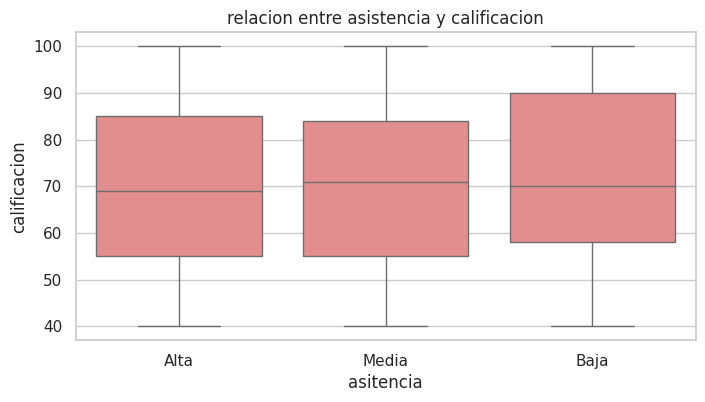

In [353]:
sns.boxplot(data=data_set_limpio, x="asistencia", y="calificacion_final", color="lightcoral")
plt.title("relacion entre asistencia y calificacion")
plt.xlabel("asitencia")
plt.ylabel("calificacion")
plt.show()

vemos que sin importar el tipo de asistencia de los alumnos todos aprueban con mas de 70, ya que las notas de aprobacion estan entres los 55 a 90 puntos (la asistencia no afecta la nota)

In [354]:
mi_pregunta = "¿cual es la relacion ente edad y calificacion?"
variables = ["edad", "calificacion_final"]
tipos = ["numerica","numerica"]
para_quien = "mostrar"

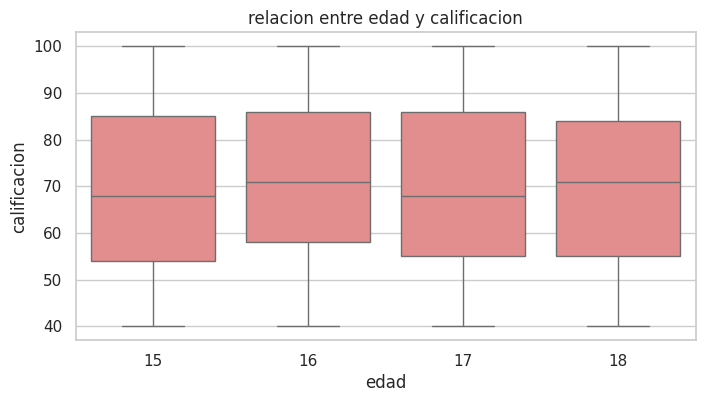

In [355]:
sns.boxplot(data=data_set_limpio, x="edad", y="calificacion_final",color="lightcoral")
plt.title("relacion entre edad y calificacion")
plt.xlabel("edad")
plt.ylabel("calificacion")
plt.show()

En este segundo grafico podemos observar donde se mide el 50% de los estudiantes con respecto a la nota, por lo que podemos ver, este 50% se mantiene agrupado en notas con 30 puntos de distancia, siempre teniendo en cuenta en rango de notas para estar aprobado que va de los 40 a los 100 puntos. En sintesis, no hay diferencia de notas con respecto a la edad

In [356]:
mi_pregunta = "¿cual es la relacion entre horas_estudio y calificacion?"
variables = ["horas_estudio", "calificacion_final"]
tipos = ["categorica","numerica"]
para_quien = "mostrar"

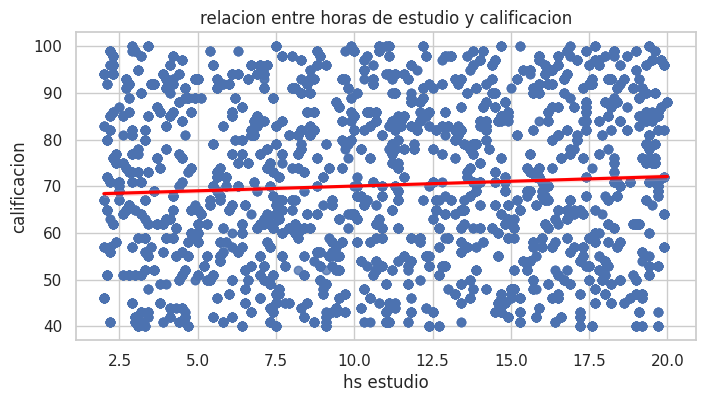

In [357]:
sns.regplot(data=data_set_limpio, x="horas_estudio", y="calificacion_final", line_kws={"color": "red"})
plt.title("relacion entre horas de estudio y calificacion")
plt.xlabel("hs estudio")
plt.ylabel("calificacion")
plt.show()

En este grafico de dispercion podemos ver que el promedio de notas por alumnos aprobados se mantiene en 70 puntos y que no se muestra una gran diferencia con respecto a las horas de estudio, ya que no se observa que mas cantidad de horas estudiadas coresponda a mayor nota.

In [358]:
mi_pregunta = "¿cual es la relacion entre el nivel academico de los padres y la  calificacion de los estudiantes?"
variables = ["nivel_educativo_padres", "calificacion_final"]
tipos = ["categorica","numerica"]
para_quien = "mostrar"

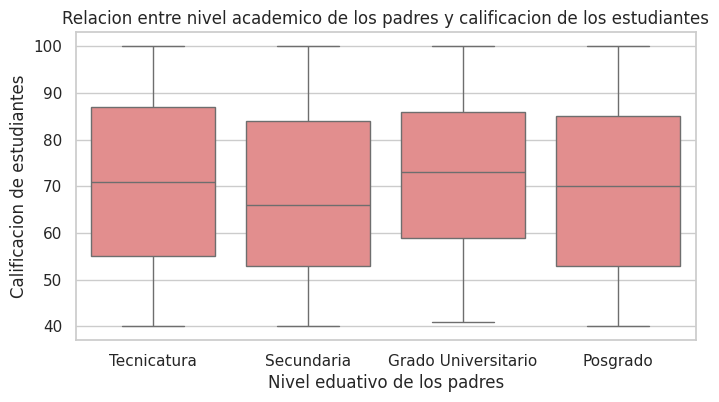

In [359]:
sns.boxplot(data=data_set_limpio, x="nivel_educativo_padres", y="calificacion_final",color="lightcoral")
plt.title("Relacion entre nivel academico de los padres y calificacion de los estudiantes")
plt.xlabel("Nivel eduativo de los padres")
plt.ylabel("Calificacion de estudiantes")
plt.show()

En este gráfico podemos observar que las notas del 50% de los estudiantes se mantienen al rededor de los 70 puntos de calificación (mediana) y que la dispersión general de las notas es prácticamente idéntica en todos los niveles. Esto nos indica que el nivel académico de los padres de estos estudiantes no influye en la nota final del mismo, mostrando un comportamiento homogéneo.

### Análisis de dos variables categóricas

Queremos responder a la pregunta: ¿Existe alguna relación o diferencia en la distribución del nivel educativo de los padres según el género del estudiante? y de ser asi ¿influye en el rendimiento academico del estudiante?

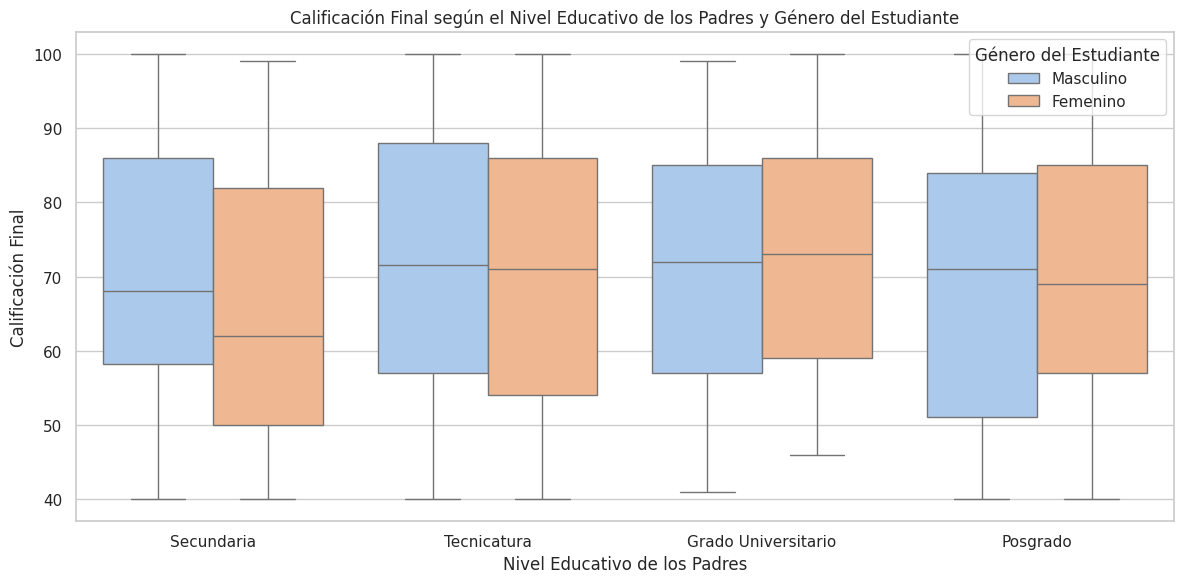

In [360]:
mi_pregunta = "¿Cómo influye la combinación del nivel educativo de los padres y el género en la calificación final?"
variables = ["nivel_educativo_padres", "genero", "calificacion_final"]
tipos = ["categorica", "categorica", "numerica"]
para_quien = "mostrar"

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=data_set_limpio,
    x="nivel_educativo_padres",
    y="calificacion_final",
    hue="genero",
    palette="pastel",
    order=["Secundaria", "Tecnicatura", "Grado Universitario", "Posgrado"]
)

plt.title("Calificación Final según el Nivel Educativo de los Padres y Género del Estudiante")
plt.xlabel("Nivel Educativo de los Padres")
plt.ylabel("Calificación Final")
plt.legend(title="Género del Estudiante", loc="upper right")
plt.tight_layout()
plt.show()

En este ultimo grafico podemos observar que el reusltado del analisis nos dice que el 50% de los hombres con padres con nivel educativo de secundaria y tecnicaturas aprueban con notas entre 60 y 90 puntos mientras que las mujeres lo hacen con notas de 40 a 80, una leve diferencia. Por otro lado, los estudiantes con padres universitarios o en posgrados se mantienen bastante bastante parejos. De nuevo volvemos a ver que los resultados se mantienen parejos.

## Conclusión Final

En este proyecto de análisis de datos hemos examinado detalladamente el rendimiento académico de una clase de estudiantes utilizando un conjunto de datos simulado de **12,000 registros**, con el fin de realizar una práctica estadística y de limpieza completa.

### 1. Diagnóstico e Inocuidad de los Datos
Comenzamos realizando una fase de inspección y diagnóstico donde pudimos verificar:
* La ausencia total de valores nulos o registros duplicados.
* La correcta asignación y correspondencia de formatos y tipos de datos en cada columna.
* La inexistencia de varianza nula o rangos anómalos.

Tras asegurar la consistencia del dataset, procedimos a crear métricas derivadas y evaluar las correlaciones entre las variables cuantitativas y cualitativas de interés.

### 2. Hallazgos del Análisis Exploratorio
Logramos evaluar exhaustivamente la relación de factores clave como el género, la edad, el nivel de asistencia, el tiempo de estudio y la educación de los padres respecto a la **calificación final**:

* **Edad y Rendimiento:** La edad promedio de los alumnos es de **16 años** (siendo también el valor más repetido) y logramos comprobar mediante correlaciones casi nulas que la edad no influye en absoluto en la nota final de los estudiantes.
* **Efecto de la Asistencia:** Aunque la asistencia es mayoritariamente alta (~61.3%), las notas de aprobación central se mantienen estables entre los 55 y 90 puntos sin importar si el alumno posee asistencia Alta, Media o Baja.
* **Educación de los Padres e Interacción de Género:** El nivel educativo de los padres se concentra principalmente en Tecnicaturas (~38.6%) y Secundaria (~31.4%). Mediante un análisis visual agrupado, identificamos una sutil diferencia en los hogares con educación de secundaria y técnica, donde el 50% de los hombres aprueba con notas de **60 a 90 puntos**, mientras que las mujeres lo hacen entre **40 y 80 puntos**. En contraste, para padres con títulos universitarios o de posgrado, el rendimiento por género es sumamente homogéneo.
* **Horas de Estudio y Métrica Derivada:** El promedio de estudio es de casi 11 horas semanales. Al calcular nuestra métrica derivada de tiempo por punto obtenido, determinamos que la moda de estudio se ubica en **0.2 horas (12 minutos) por punto de calificación**. Esto implica que para alcanzar una nota aprobatoria promedio de 70 puntos, un alumno suele requerir un aproximado de **14 horas de estudio**.

En síntesis, mediante este análisis estadístico se hace evidente que en este conjunto de datos no existe un único factor que determine drásticamente el desempeño académico. La variable que muestra un comportamiento levemente más rescatable en la distribución son las **horas de estudio dedicadas**.

---

###  Cosas Aprendidas de Gran Importancia
A lo largo del desarrollo de este cuaderno, he logrado comprender y consolidar:
1. **La importancia crucial de la limpieza de datos**, garantizando que cualquier interpretación posterior parta de una base confiable, limpia y libre de distorsiones.
2. **La utilidad de plantear preguntas de investigación precisas**, ya que estas actúan como un mapa o brújula que delimita el camino de búsqueda de respuestas durante la fase de análisis.
3. **La potencia de la creación de nuevas métricas**, lo que nos permite exprimir y cruzar variables para descubrir relaciones de valor que no son visibles a simple vista.
4. **La función de los gráficos y visualizaciones**, como la herramienta de comunicación definitiva que simplifica la transmisión de mensajes estadísticos complejos para que cualquier persona pueda entender los resultados de forma rápida y eficiente.